# 03 - Model Evaluation

**Task:** predict 30-day readmission (`target = 1`) for diabetic inpatient encounters.

**Evaluation rules**
- **Primary model-selection metric:** Average Precision (AP; area under the precision–recall curve). ROC-AUC is a secondary ranking metric.
- **Operating point:** use the threshold selected on validation data (recomputed from the saved validation predictions; see `run_summary.json`). Report Recall, Precision and F1 at that threshold; do not select a threshold from the test set.
- **Final test set:** 19,802 encounters, 2,216 positives. The train set has 79,541 encounters; the modeling fit/validation split is 63,807/15,734.
- **Comparison tables:** validation metrics at threshold 0.5 are descriptive and are not directly comparable to test metrics calculated at each model's own validation-selected threshold. Ranking metrics (AP/ROC-AUC) do not depend on a threshold.
- **Bootstrap:** resample patients, not individual encounters, when patient IDs are available. This accounts for within-patient correlation.

This notebook intentionally does **not** claim ablation results, SHAP/feature importance results, or verified external-paper baselines unless those analyses and sources have actually been checked. These should be added only after running the corresponding analysis.

In [40]:
from pathlib import Path
import json, warnings, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    confusion_matrix, brier_score_loss, log_loss, precision_recall_curve,
    roc_curve, auc, classification_report
)
from sklearn.calibration import calibration_curve
warnings.filterwarnings("ignore")
SEED = 42
N_BOOT = 2000

In [41]:
# Find project root whether the notebook is launched from repo root or notebooks/
ROOT = Path.cwd().resolve()
while not ((ROOT / "data").is_dir() and (ROOT / "outputs").is_dir()) and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not ((ROOT / "data").is_dir() and (ROOT / "outputs").is_dir()):
    raise FileNotFoundError("Cannot find project root containing data/ and outputs/. Open this notebook inside the project.")
DATA, OUT = ROOT / "data", ROOT / "outputs"
EVAL = OUT / "evaluation"
FIG, TAB = EVAL / "figures", EVAL / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

test = pd.read_csv(DATA / "test_clean.csv")
pred_path = OUT / "test_predictions.csv"
if pred_path.exists():
    saved = pd.read_csv(pred_path)
    if {"y_true", "probability"}.issubset(saved.columns):
        y = saved["y_true"].to_numpy(dtype=int)
        p = saved["probability"].to_numpy(dtype=float)
    else:
        raise ValueError(f"{pred_path} must contain columns y_true and probability.")
else:
    raise FileNotFoundError("Missing outputs/test_predictions.csv. Run the modeling notebook first to export final test predictions.")

assert len(test) == len(y) == len(p), "Prediction/test row counts do not match."
assert np.array_equal(test["target"].to_numpy(dtype=int), y), "Saved predictions are not aligned with test_clean.csv."
assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), "Predicted probabilities must be finite and in [0, 1]."

# Single source of truth: recompute the F1-optimal threshold from saved validation predictions.
# Không lấy ngưỡng từ best_params.json vì file này có thể cũ/lệch với lần chạy hiện tại.
val_path = EVAL / "val_predictions_tuned_catboost.csv"
if not val_path.exists():
    raise FileNotFoundError(
        f"Missing {val_path}. Run 02_modeling first and export validation predictions "
        "with columns y_true, probability."
    )
val_pred = pd.read_csv(val_path)
if not {"y_true", "probability"}.issubset(val_pred.columns):
    raise ValueError("val_predictions_tuned_catboost.csv must contain y_true, probability.")
vy = val_pred["y_true"].to_numpy(dtype=int)
vp = val_pred["probability"].to_numpy(dtype=float)
if len(vy) == 0 or len(vy) != len(vp):
    raise ValueError("Validation predictions are empty or y_true/probability lengths differ.")
if not np.isin(vy, [0, 1]).all() or np.unique(vy).size != 2:
    raise ValueError("Validation y_true must contain both classes coded as 0 and 1.")
if not np.isfinite(vp).all() or ((vp < 0) | (vp > 1)).any():
    raise ValueError("Validation probabilities must be finite and in [0, 1].")
prec_v, rec_v, thr_v = precision_recall_curve(vy, vp)
f1_v = np.divide(2*prec_v[:-1]*rec_v[:-1], prec_v[:-1]+rec_v[:-1],
                 out=np.zeros_like(prec_v[:-1]), where=(prec_v[:-1]+rec_v[:-1]) != 0)
THR = float(thr_v[int(np.argmax(f1_v))])
# Synchronize downstream metadata so future runs do not silently use a different threshold.
meta_path = OUT / "best_params.json"
meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
meta["threshold"] = THR
meta["threshold_source"] = "outputs/evaluation/val_predictions_tuned_catboost.csv; max F1 on validation"
meta_path.write_text(json.dumps(meta, indent=2))
thr_path_sync = EVAL / "model_thresholds.json"
if thr_path_sync.exists():
    threshold_map = json.loads(thr_path_sync.read_text())
    threshold_map["Tuned CatBoost"] = THR
    thr_path_sync.write_text(json.dumps(threshold_map, indent=2))
print(f"Project: {ROOT}")
print(f"Train encounters: {len(pd.read_csv(DATA / 'train_clean.csv')):,}")
print(f"Test encounters: {len(y):,} | positive cases: {int(y.sum()):,} ({y.mean():.2%})")
print(f"Validation rows: {len(vy):,} | positives: {int(vy.sum()):,}")
print(f"Final model: Tuned CatBoost | canonical validation threshold: {THR:.6f}")

Project: /Users/vianhbui/Downloads/diabetes-readmission-prediction
Train encounters: 79,541
Test encounters: 19,802 | positive cases: 2,216 (11.19%)
Validation rows: 15,734 | positives: 1,802
Final model: Tuned CatBoost | canonical validation threshold: 0.135506


## 1. Headline test performance

AP is the primary ranking metric because the positive class is uncommon and AP directly reflects precision–recall performance. ROC-AUC is reported as a complementary ranking metric. Recall, Precision and F1 are calculated at the validation-selected threshold above. No threshold is optimized on the test set.

In [42]:
def decision_metrics(y_true, prob, threshold):
    y_true = np.asarray(y_true, dtype=int)
    pred_label = (np.asarray(prob) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred_label, labels=[0, 1]).ravel()
    precision = precision_score(y_true, pred_label, zero_division=0)
    recall = recall_score(y_true, pred_label, zero_division=0)
    f1 = f1_score(y_true, pred_label, zero_division=0)
    return {
        "Threshold": threshold, "ROC-AUC": roc_auc_score(y_true, prob),
        "AP": average_precision_score(y_true, prob), "Recall": recall,
        "Precision": precision, "F1": f1, "Specificity": tn/(tn+fp) if tn+fp else np.nan,
        "Accuracy": (tp+tn)/(tp+tn+fp+fn), "Brier": brier_score_loss(y_true, prob),
        "Log loss": log_loss(y_true, np.clip(prob, 1e-12, 1-1e-12)),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Flagged %": 100*(tp+fp)/len(y_true)
    }

headline = pd.DataFrame([decision_metrics(y, p, THR)], index=["Tuned CatBoost"])
display(headline.T.rename(columns={0:"Value"}).round(4))
headline.to_csv(TAB / "01_headline_metrics.csv")

,Tuned CatBoost
Threshold,0.1355
ROC-AUC,0.6765
AP,0.2453
Recall,0.4585
Precision,0.2018
F1,0.2802
Specificity,0.7715
Accuracy,0.7364
Brier,0.0936
Log loss,0.3274


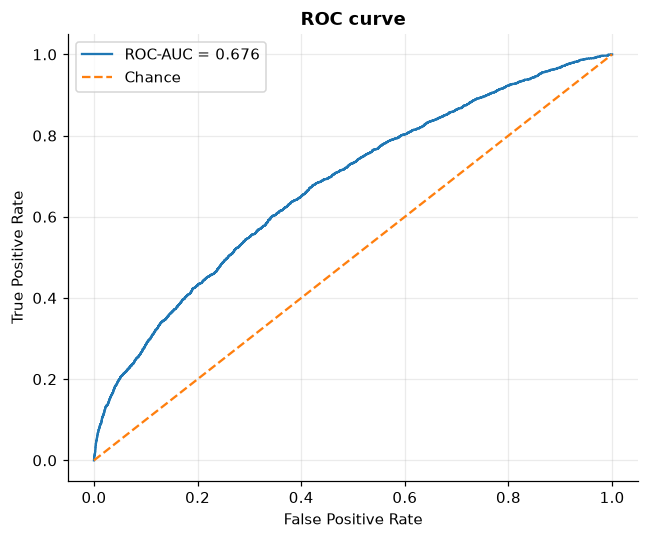

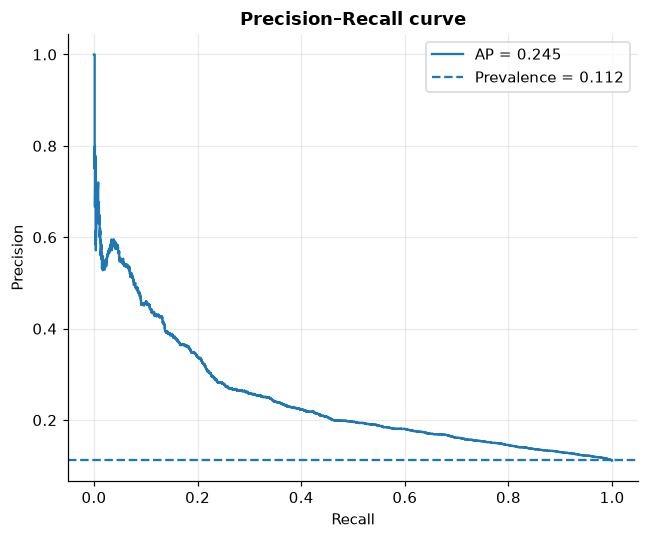

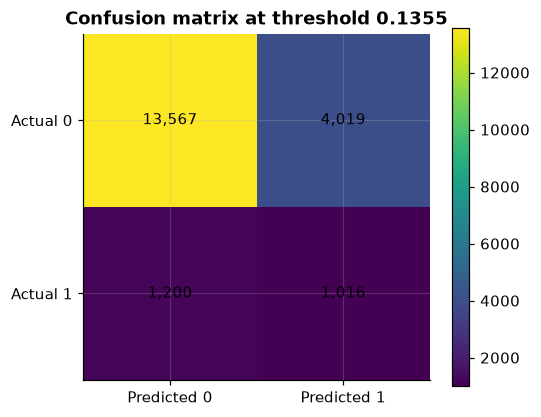

In [43]:
# ROC and Precision–Recall curves
fpr, tpr, _ = roc_curve(y, p)
prec_curve, rec_curve, _ = precision_recall_curve(y, p)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y,p):.3f}")
ax.plot([0,1], [0,1], linestyle="--", label="Chance")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve")
ax.legend(); fig.tight_layout(); fig.savefig(FIG/"01_roc_curve.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rec_curve, prec_curve, label=f"AP = {average_precision_score(y,p):.3f}")
ax.axhline(y.mean(), linestyle="--", label=f"Prevalence = {y.mean():.3f}")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve")
ax.legend(); fig.tight_layout(); fig.savefig(FIG/"01_pr_curve.png", dpi=180); plt.show()

tn, fp, fn, tp = confusion_matrix(y, p >= THR, labels=[0,1]).ravel()
fig, ax = plt.subplots(figsize=(5,4))
im = ax.imshow([[tn,fp],[fn,tp]], interpolation="nearest")
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Predicted 0","Predicted 1"],
       yticklabels=["Actual 0","Actual 1"], title=f"Confusion matrix at threshold {THR:.4f}")
for i,row in enumerate([[tn,fp],[fn,tp]]):
    for j,val in enumerate(row): ax.text(j,i,f"{val:,}",ha="center",va="center")
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(FIG/"01_confusion_matrix.png", dpi=180); plt.show()

## 2. Patient-cluster bootstrap confidence intervals

The same patient may contribute multiple encounters, so an encounter-level bootstrap can understate uncertainty. The code below uses `data/test_patient_groups.csv` if available. If it is absent, it reconstructs patient IDs from `input/diabetic_data.csv` using the same exclusions and `GroupShuffleSplit` seed as the EDA notebook, then verifies row alignment against the cleaned test set.

In [45]:
def get_test_patient_groups():
    group_file = DATA / "test_patient_groups.csv"
    if group_file.exists():
        groups = pd.read_csv(group_file)["patient_nbr"].to_numpy()
        if len(groups) != len(test):
            raise ValueError("test_patient_groups.csv row count does not match test_clean.csv.")
        return groups, "saved data/test_patient_groups.csv"
    raw_path = ROOT / "input" / "diabetic_data.csv"
    if not raw_path.exists():
        raise FileNotFoundError("Patient IDs unavailable: add data/test_patient_groups.csv from the EDA notebook.")
    from sklearn.model_selection import GroupShuffleSplit
    raw = pd.read_csv(raw_path).replace("?", np.nan)
    raw = raw[~raw["discharge_disposition_id"].isin([11,13,14,19,20,21])].reset_index(drop=True)
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(raw, groups=raw["patient_nbr"]))
    raw_test = raw.iloc[test_idx].reset_index(drop=True)
    if len(raw_test) != len(test):
        raise ValueError("Reconstructed test rows do not align with test_clean.csv; use saved test_patient_groups.csv generated by EDA.")
    if not np.array_equal(raw_test["readmitted"].eq("<30").astype(int).to_numpy(), test["target"].to_numpy(dtype=int)):
        raise ValueError("Reconstructed patient IDs fail target alignment check.")
    for col in ["age", "gender"]:
        if col in test and not np.array_equal(raw_test[col].astype(str).to_numpy(), test[col].astype(str).to_numpy()):
            raise ValueError(f"Reconstructed patient IDs fail {col} alignment check.")
    return raw_test["patient_nbr"].to_numpy(), "reconstructed from raw input and verified"

GROUPS, GROUP_SOURCE = get_test_patient_groups()
assert len(GROUPS) == len(y)
print(f"Patient grouping source: {GROUP_SOURCE}")
print(f"Test encounters={len(y):,}; unique patients={pd.Series(GROUPS).nunique():,}")

Patient grouping source: saved data/test_patient_groups.csv
Test encounters=19,802; unique patients=13,998


In [46]:
def cluster_bootstrap_ci(y, p, threshold, groups, n_boot=1000, seed=42):
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    # Group rows in one grouped pass (avoid O(n_rows * n_patients) repeated scans).
    group_rows = [idx.to_numpy(dtype=int) for _, idx in
                  pd.Series(np.arange(len(groups))).groupby(groups, sort=False)]
    rng = np.random.default_rng(seed)
    metrics = ["ROC-AUC", "AP", "Recall", "Precision", "F1", "Specificity"]
    samples = {m: [] for m in metrics}
    if len(y) == 0 or len(y) != len(p) or len(y) != len(groups):
        raise ValueError("y, p, and groups must have the same non-zero length.")
    if n_boot < 100:
        raise ValueError("Use at least 100 bootstrap replicates; 2,000 is recommended.")
    if pd.isna(groups).any():
        raise ValueError("Patient group IDs contain missing values.")
    if np.unique(y).size != 2:
        raise ValueError("The full test set must contain both target classes.")
    point = decision_metrics(y, p, threshold)
    for _ in range(n_boot):
        selected = rng.integers(0, len(group_rows), size=len(group_rows))
        ix = np.concatenate([group_rows[j] for j in selected])
        yb, pb = y[ix], p[ix]
        if np.unique(yb).size < 2:
            continue
        dm = decision_metrics(yb, pb, threshold)
        for m in metrics: samples[m].append(dm[m])
    rows=[]
    for m in metrics:
        vals=np.asarray(samples[m], dtype=float)
        if len(vals) < max(100, int(0.8 * n_boot)):
            raise RuntimeError(
                f"Only {len(vals)} valid bootstrap replicates for {m}; "
                "too many samples lacked both classes. Check target and patient groups."
            )
        rows.append({"Metric":m, "Estimate":point[m],
                     "CI low":np.quantile(vals,.025), "CI high":np.quantile(vals,.975),
                     "Bootstrap replicates":len(vals), "Resampling unit":"patient"})
    return pd.DataFrame(rows)

ci = cluster_bootstrap_ci(y, p, THR, GROUPS, N_BOOT, SEED)
ci["Estimate [95% CI]"] = ci.apply(lambda r: f"{r['Estimate']:.3f} [{r['CI low']:.3f}, {r['CI high']:.3f}]", axis=1)
display(ci[["Metric","Estimate [95% CI]"]].set_index("Metric"))
ci.to_csv(TAB/"01_headline_metrics_cluster_bootstrap_ci.csv", index=False)

,Estimate [95% CI]
Metric,
ROC-AUC,"0.676 [0.662, 0.690]"
AP,"0.245 [0.222, 0.268]"
Recall,"0.458 [0.431, 0.486]"
Precision,"0.202 [0.188, 0.216]"
F1,"0.280 [0.262, 0.298]"
Specificity,"0.771 [0.764, 0.779]"


## 3. Baseline reference and model-comparison caveat

A classifier that flags nobody can still achieve high accuracy when positives are rare. The comparison below is illustrative only. Do not interpret the validation table at threshold 0.5 as equivalent to the test comparison at validation-selected thresholds.

**Why can the tables differ?** The modeling notebook's validation table reports threshold-dependent Precision/Recall/F1 at the fixed cutoff 0.5. This evaluation recomputes the operating threshold from the saved validation predictions and records the exact value in `run_summary.json`; it does not rely on a hard-coded threshold. In addition, validation and test are different data splits. AP and ROC-AUC are threshold-free, so they are the appropriate metrics for comparing ranking quality across splits; final performance claims should come from the held-out test set.

In [47]:
prev = float(np.mean(y))
naive = pd.DataFrame([
    {"Model":"Flag nobody", "Accuracy":1-prev, "Recall":0.0, "Precision":np.nan, "F1":0.0, "AP":prev, "ROC-AUC":0.5},
    {"Model":"Flag everybody", "Accuracy":prev, "Recall":1.0, "Precision":prev, "F1":2*prev/(1+prev), "AP":prev, "ROC-AUC":0.5},
    {"Model":"Tuned CatBoost", "Accuracy":headline.iloc[0]["Accuracy"], "Recall":headline.iloc[0]["Recall"],
     "Precision":headline.iloc[0]["Precision"], "F1":headline.iloc[0]["F1"],
     "AP":headline.iloc[0]["AP"], "ROC-AUC":headline.iloc[0]["ROC-AUC"]}
])
display(naive.round(4).set_index("Model"))
naive.to_csv(TAB/"02_naive_reference.csv", index=False)

,Accuracy,Recall,Precision,F1,AP,ROC-AUC
Model,,,,,,
Flag nobody,0.8881,0.0000,NaN,0.0000,0.1119,0.5000
Flag everybody,0.1119,1.0000,0.1119,0.2013,0.1119,0.5000
Tuned CatBoost,0.7364,0.4585,0.2018,0.2802,0.2453,0.6765


## 4. Common-test-set model comparison

`outputs/evaluation/model_predictions.csv` contains probabilities for candidate models on the same test encounters. Each model's decision threshold comes from its validation split (`model_thresholds.json`); the tuned model uses the canonical saved threshold. Compare models primarily by AP and ROC-AUC. Recall/Precision/F1 are operating-point metrics and can differ because thresholds differ.

,Model,Threshold,AP,ROC-AUC,Recall,Precision,F1,Specificity,Flagged %
0,Tuned CatBoost,0.1355,0.2453,0.6765,0.4585,0.2018,0.2802,0.7715,25.4267
1,CatBoost,0.1365,0.2424,0.6754,0.4531,0.2043,0.2816,0.7777,24.8157
2,CatBoost + Class Weight,0.5355,0.2322,0.6732,0.4883,0.1986,0.2824,0.7518,27.5073
3,Random Forest,0.1330,0.2229,0.6669,0.4743,0.1966,0.2780,0.7558,26.9973
4,Logistic Regression,0.1265,0.2203,0.6665,0.4973,0.1936,0.2787,0.7389,28.7496
5,Logistic Regression + Class Weight,0.5374,0.2194,0.6678,0.4810,0.1961,0.2787,0.7516,27.4467
6,Random Forest + Class Weight,0.5256,0.2142,0.6651,0.4449,0.2019,0.2778,0.7784,24.6591
7,Decision Tree + Class Weight,0.6174,0.2033,0.6457,0.2500,0.2326,0.2410,0.8961,12.0291
8,Decision Tree,0.1351,0.2031,0.6470,0.4395,0.1891,0.2644,0.7625,26.0125


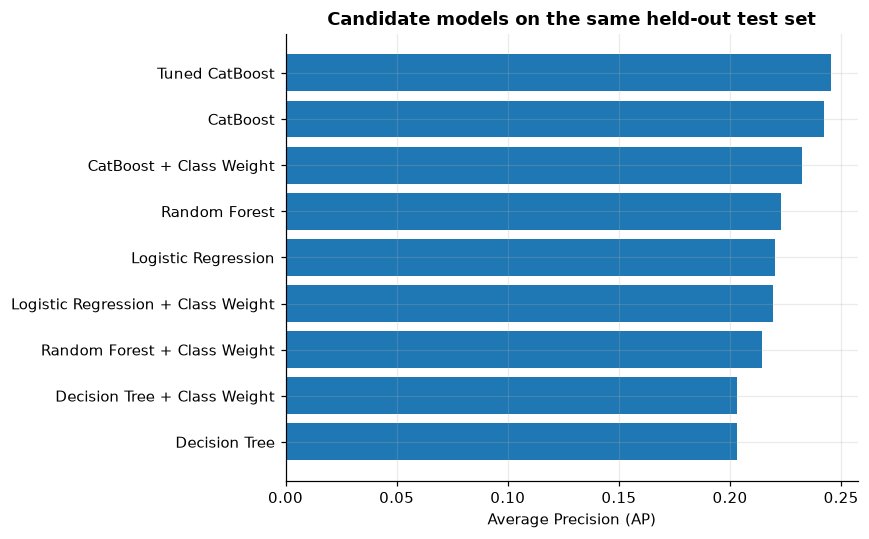

In [48]:
mp_path = EVAL / "model_predictions.csv"
thr_path = EVAL / "model_thresholds.json"
if mp_path.exists() and thr_path.exists():
    mp = pd.read_csv(mp_path)
    thresholds_by_model = json.loads(thr_path.read_text())
    if "y_true" not in mp or len(mp) != len(y) or not np.array_equal(mp["y_true"].to_numpy(dtype=int), y):
        raise ValueError(
            "model_predictions.csv is not row-aligned with outputs/test_predictions.csv. "
            "Do not compare models until both files refer to the same ordered test rows."
        )

    # The tuned-model column in older model_predictions.csv may come from another fit/run.
    # Use the canonical final test predictions from outputs/test_predictions.csv for this model,
    # so the headline and comparison table cannot silently report different CatBoost probabilities.
    if "Tuned CatBoost" in mp.columns:
        old_tuned = mp["Tuned CatBoost"].to_numpy(dtype=float)
        tuned_match = np.allclose(old_tuned, p, rtol=1e-7, atol=1e-8)
        if not tuned_match:
            max_diff = float(np.max(np.abs(old_tuned - p)))
            print(
                "WARNING: Tuned CatBoost probabilities in model_predictions.csv differ from "
                f"outputs/test_predictions.csv (max absolute difference={max_diff:.6f}). "
                "For this evaluation run, replacing that column in memory with the canonical "
                "outputs/test_predictions.csv probabilities. The original file is not modified."
            )
        mp["Tuned CatBoost"] = p
    else:
        mp["Tuned CatBoost"] = p
        print("Added canonical Tuned CatBoost probabilities from outputs/test_predictions.csv.")

    model_cols = [c for c in mp.columns if c != "y_true"]
    rows = []
    for model_name in model_cols:
        prob = mp[model_name].to_numpy(dtype=float)
        if not np.isfinite(prob).all() or ((prob < 0) | (prob > 1)).any():
            raise ValueError(f"Invalid probabilities in model_predictions.csv column: {model_name}")
        if model_name == "Tuned CatBoost":
            threshold = THR
        else:
            if model_name not in thresholds_by_model:
                raise KeyError(
                    f"No validation-selected threshold for '{model_name}' in model_thresholds.json. "
                    "Add/export the threshold from validation; do not select it on test data."
                )
            threshold = float(thresholds_by_model[model_name])
            if not np.isfinite(threshold) or not 0 <= threshold <= 1:
                raise ValueError(f"Invalid threshold for model '{model_name}': {threshold}")
        dm = decision_metrics(y, prob, threshold)
        rows.append({"Model": model_name, **dm})
    comparison = pd.DataFrame(rows).sort_values(["AP", "ROC-AUC"], ascending=False).reset_index(drop=True)
    display(comparison[["Model","Threshold","AP","ROC-AUC","Recall","Precision","F1","Specificity","Flagged %"]].round(4))
    comparison.to_csv(TAB/"03_model_comparison_test.csv", index=False)
    fig, ax = plt.subplots(figsize=(8,5))
    plot_df = comparison.sort_values("AP")
    ax.barh(plot_df["Model"], plot_df["AP"])
    ax.set(xlabel="Average Precision (AP)", title="Candidate models on the same held-out test set")
    fig.tight_layout(); fig.savefig(FIG/"03_model_comparison_ap.png", dpi=180); plt.show()
else:
    print("Model comparison skipped: outputs/evaluation/model_predictions.csv or model_thresholds.json is missing. Run src/compare_models.py first.")


## 4. Threshold sensitivity (test set used for description only)

This plot describes how metrics change with a threshold; it does **not** select a new threshold. The operating threshold remains the value chosen on validation data.

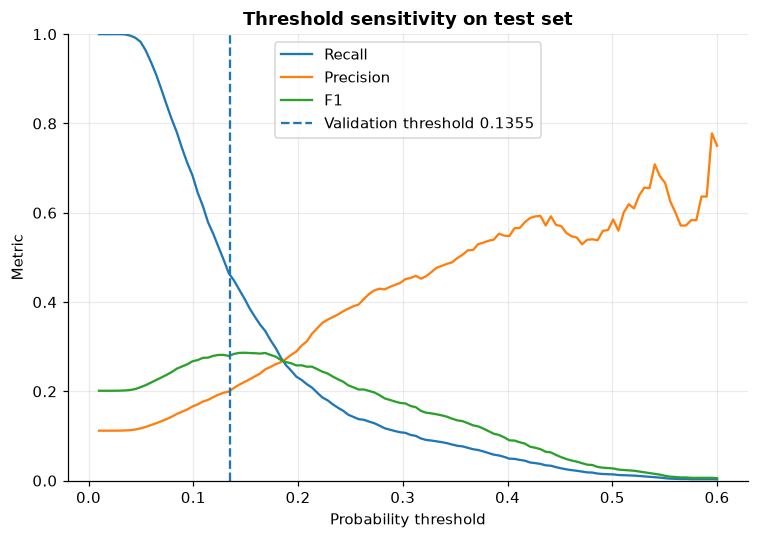

In [49]:
thresholds = np.linspace(0.01, 0.60, 120)
rows=[]
for t in thresholds:
    d=decision_metrics(y,p,float(t))
    rows.append({"Threshold":t,"Recall":d["Recall"],"Precision":d["Precision"],"F1":d["F1"],"Flagged %":d["Flagged %"]})
sweep=pd.DataFrame(rows)
sweep.to_csv(TAB/"04_threshold_sweep.csv",index=False)
fig,ax=plt.subplots(figsize=(7,5))
for col in ["Recall","Precision","F1"]: ax.plot(sweep["Threshold"],sweep[col],label=col)
ax.axvline(THR,linestyle="--",label=f"Validation threshold {THR:.4f}")
ax.set(xlabel="Probability threshold",ylabel="Metric",ylim=(0,1),title="Threshold sensitivity on test set")
ax.legend();fig.tight_layout();fig.savefig(FIG/"04_threshold_sensitivity.png",dpi=180);plt.show()

## 5. Calibration

Calibration measures whether predicted probabilities correspond to observed frequencies. The results are descriptive and do not change the operating threshold.

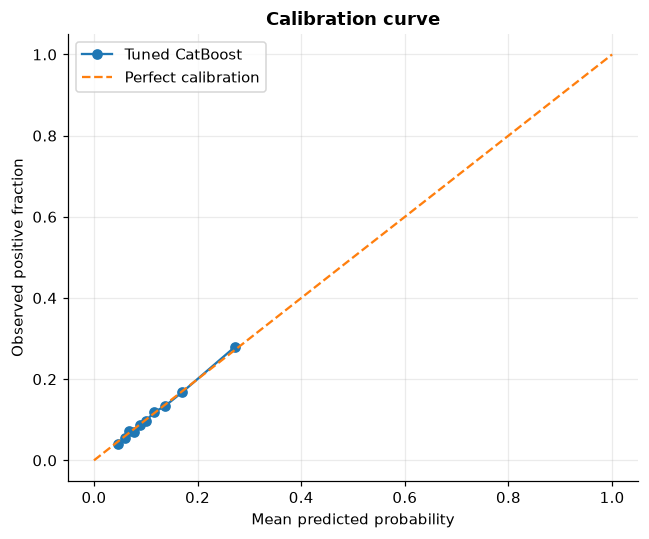

,Brier score,Log loss,Prevalence
0,0.0936,0.3274,0.1119


In [50]:
frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(mean_pred,frac_pos,marker="o",label="Tuned CatBoost")
ax.plot([0,1],[0,1],linestyle="--",label="Perfect calibration")
ax.set(xlabel="Mean predicted probability",ylabel="Observed positive fraction",title="Calibration curve")
ax.legend();fig.tight_layout();fig.savefig(FIG/"07_calibration.png",dpi=180);plt.show()
cal_summary = pd.DataFrame([{"Brier score":brier_score_loss(y,p),
                             "Log loss":log_loss(y,np.clip(p,1e-12,1-1e-12)),
                             "Prevalence":prev}])
display(cal_summary.round(4))
cal_summary.to_csv(TAB/"07_calibration_summary.csv",index=False)

## 6. Error and subgroup analysis

These summaries are exploratory. Small groups can produce unstable estimates; do not make fairness or clinical claims from raw subgroup differences alone.

In [51]:
pred_label=(p>=THR).astype(int)
errors=test.copy()
errors["y_true"]=y; errors["probability"]=p; errors["predicted"]=pred_label
errors["error_type"]=np.select(
    [(y==1)&(pred_label==1),(y==1)&(pred_label==0),(y==0)&(pred_label==1)],
    ["TP","FN","FP"], default="TN")
errors[["y_true","probability","predicted","error_type"]].to_csv(EVAL/"test_error_labels.csv",index=False)

subgroup_rows=[]
for col in ["age","gender","race","diag_1_group","discharge_disposition_id"]:
    if col not in test.columns: continue
    for group, ix in test.groupby(col, dropna=False, observed=True).indices.items():
        ix=np.asarray(ix)
        yy=y[ix]; pp=p[ix]; ll=pred_label[ix]
        pos=int(yy.sum())
        subgroup_rows.append({"Feature":col,"Group":str(group),"n":len(ix),"Positives":pos,
          "Prevalence":float(yy.mean()),"AP":average_precision_score(yy,pp) if np.unique(yy).size>1 else np.nan,
          "ROC-AUC":roc_auc_score(yy,pp) if np.unique(yy).size>1 else np.nan,
          "Recall":recall_score(yy,ll,zero_division=0),"Precision":precision_score(yy,ll,zero_division=0),
          "Flag":"small sample" if len(ix)<500 or pos<50 else ""})
subgroups=pd.DataFrame(subgroup_rows)
display(subgroups.round(3))
subgroups.to_csv(TAB/"07_subgroup_performance.csv",index=False)

,Feature,Group,n,Positives,Prevalence,AP,ROC-AUC,Recall,Precision,Flag
0,age,[0-10),29,1,0.034,0.045,0.250,0.000,0.000,small sample
1,age,[10-20),138,9,0.065,0.216,0.597,0.222,0.200,small sample
2,age,[20-30),388,60,0.155,0.495,0.872,0.817,0.374,small sample
3,age,[30-40),729,77,0.106,0.327,0.726,0.558,0.265,
4,age,[40-50),1909,202,0.106,0.211,0.669,0.371,0.189,
5,age,[50-60),3469,356,0.103,0.282,0.715,0.455,0.255,
6,age,[60-70),4266,464,0.109,0.221,0.657,0.412,0.198,
7,age,[70-80),5040,587,0.116,0.231,0.663,0.492,0.193,
8,age,[80-90),3287,390,0.119,0.234,0.648,0.459,0.168,
9,age,[90-100),547,70,0.128,0.181,0.531,0.371,0.151,


In [52]:
# paired patient-level bootstrap on the SAME resamples as the table above (no extra resampling needed)
pw = pairwise_cluster(y, proba, thr_m, draws, reference="Tuned CatBoost")
fmt = pw.copy()
for c in [c for c in fmt.columns if c.startswith("p ")]:
    fmt[c] = fmt[c].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
display(fmt[["Model", "ΔAUC", "ΔAUC 95% CI", "p AUC (Holm)", "ΔAP", "ΔAP 95% CI", "p AP (Holm)", "ΔF1", "ΔF1 95% CI", "p F1 (Holm)",
             "ΔRecall", "p Recall (Holm)", "ΔSpecificity", "p Specificity (Holm)", "p DeLong (indep., reference) (Holm)"]].set_index("Model").round(4))
pw.to_csv(TAB / "03_pairwise_tests_vs_tuned_catboost.csv", index=False)

,ΔAUC,ΔAUC 95% CI,p AUC (Holm),ΔAP,ΔAP 95% CI,p AP (Holm),ΔF1,ΔF1 95% CI,p F1 (Holm),ΔRecall,p Recall (Holm),ΔSpecificity,p Specificity (Holm),"p DeLong (indep., reference) (Holm)"
Model,,,,,,,,,,,,,,
Logistic Regression,0.0099,"[+0.0046, +0.0152]",0.008,0.0250,"[+0.0163, +0.0336]",0.008,0.0078,"[-0.0008, +0.0166]",0.312,-0.0677,0.008,0.0633,0.008,<0.001
Decision Tree,0.0295,"[+0.0215, +0.0374]",0.008,0.0422,"[+0.0313, +0.0532]",0.008,0.0221,"[+0.0114, +0.0329]",0.008,-0.0099,0.282,0.0397,0.008,<0.001
Random Forest,0.0095,"[+0.0061, +0.0132]",0.008,0.0225,"[+0.0144, +0.0320]",0.008,0.0085,"[+0.0012, +0.0163]",0.162,-0.0447,0.008,0.0465,0.008,<0.001
CatBoost,0.0011,"[-0.0013, +0.0035]",0.370,0.0029,"[-0.0018, +0.0075]",0.231,0.0049,"[-0.0010, +0.0104]",0.312,-0.0235,0.008,0.0246,0.008,0.350
Logistic Regression + Class Weight,0.0087,"[+0.0034, +0.0139]",0.008,0.0259,"[+0.0172, +0.0349]",0.008,0.0078,"[-0.0009, +0.0164]",0.312,-0.0514,0.008,0.0507,0.008,0.003
Decision Tree + Class Weight,0.0308,"[+0.0231, +0.0387]",0.008,0.0420,"[+0.0314, +0.0522]",0.008,0.0455,"[+0.0305, +0.0605]",0.008,0.1796,0.008,-0.0938,0.008,<0.001
Random Forest + Class Weight,0.0114,"[+0.0077, +0.0153]",0.008,0.0311,"[+0.0215, +0.0408]",0.008,0.0087,"[-0.0000, +0.0175]",0.265,-0.0153,0.092,0.0238,0.008,<0.001
CatBoost + Class Weight,0.0033,"[-0.0002, +0.0070]",0.140,0.0131,"[+0.0063, +0.0201]",0.008,0.0041,"[-0.0035, +0.0124]",0.312,-0.0587,0.008,0.0504,0.008,0.147


## 7. What is not claimed in this evaluation

- **Feature-engineering ablation:** not computed in this notebook. To claim the seven engineered features improve performance, fit and compare otherwise identical pipelines with and without those features using the same patient-grouped split/CV and AP as the primary metric.
- **Feature importance / SHAP:** not computed here. Do not write an interpretation of individual feature effects without running a reproducible importance or SHAP analysis on the fitted model.
- **External published baselines:** omitted because the source values and evaluation protocols have not yet been verified from the original papers/pages. Add them only after checking each source and clearly documenting split, target definition, and metric.
- **Environment:** modeling was run in Google Colab and evaluation locally. Record Python and package versions for reproducibility; results may differ slightly across CatBoost/scikit-learn versions.

## 8. Export run summary

In [54]:
import platform, sklearn
try:
    import catboost
    catboost_version=catboost.__version__
except Exception:
    catboost_version="not installed in evaluation environment"
summary = {
    "final_model":"Tuned CatBoost",
    "primary_selection_metric":"Average Precision (AP)",
    "threshold_selection":"maximum F1 on validation split; threshold not re-optimized on test",
    "operating_threshold":float(THR),
    "train_encounters_expected":79541,
    "fit_encounters_expected":63807,
    "validation_encounters_expected":15734,
    "test_encounters":int(len(y)),
    "test_positive_cases":int(y.sum()),
    "test_prevalence":float(y.mean()),
    "test_unique_patients":int(pd.Series(GROUPS).nunique()),
    "bootstrap_unit":"patient",
    "bootstrap_replicates_requested":int(N_BOOT),
    "bootstrap_replicates_min_valid":int(ci["Bootstrap replicates"].min()),
    "test_prediction_source":str(pred_path.relative_to(ROOT)),
    "validation_prediction_source":str(val_path.relative_to(ROOT)),
    "threshold_metric": "F1",
    "python_version":platform.python_version(),
    "pandas_version":pd.__version__,
    "numpy_version":np.__version__,
    "scikit_learn_version":sklearn.__version__,
    "catboost_version":catboost_version
}
(EVAL/"run_summary.json").write_text(json.dumps(summary,indent=2))
display(pd.Series(summary,name="Value").to_frame())
print(f"Evaluation outputs saved under: {EVAL}")

,Value
final_model,Tuned CatBoost
primary_selection_metric,Average Precision (AP)
threshold_selection,maximum F1 on validation split; threshold not ...
operating_threshold,0.135506
train_encounters_expected,79541
fit_encounters_expected,63807
validation_encounters_expected,15734
test_encounters,19802
test_positive_cases,2216
test_prevalence,0.111908


Evaluation outputs saved under: /Users/vianhbui/Downloads/diabetes-readmission-prediction/outputs/evaluation
